In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#!unzip ../content/drive/MyDrive/music_genre_data_di.zip

In [ ]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import time
import matplotlib.pyplot as plt
import random
import librosa
import torch.optim as optim
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader

In [2]:
#!pip install torchmetrics

In [ ]:
from torchmetrics.classification import MulticlassAccuracy, MulticlassF1Score
from sklearn.metrics import confusion_matrix

Question 1 - Feedforward Neural Network:

Data Loading (mfcss): 
We define a custom class ```mfcss_dataset(Dataset)```that inherits from `Dataset`, so that it can be used with `Dataloaders` when training our model.

In [ ]:
#Class that represents the cleaned mfcss dataset used during training
class mfcss_dataset(Dataset):
    
    def __init__(self,x_data,y_data):
        self.x = x_data
        self.y = y_data

    def __len__(self):
      return len(self.y)

    def __getitem__(self, index):
       return self.x[index],self.y[index]

In [ ]:
#Loads the dataset and converts it properly from numpy to tensor. Turns string labels into integers.
def load_and_convert_mfcss(path_x,path_y):
    x = np.load(path_x)
    y = np.load(path_y)
    x = torch.from_numpy(x).float()
    labels, y = np.unique(y, return_inverse=True)
    y = torch.from_numpy(y)
    return x,y,labels

In [ ]:
#Creates our dataset objects for trainig, validation, testing
def create_dataset_mfcss(path,test_path,train_path,val_path):
    x_test,y_test,labels = load_and_convert_mfcss(test_path+"X.npy",test_path +"labels.npy")
    test_dataset = mfcss_dataset(x_test,y_test)

    x_train,y_train,labels = load_and_convert_mfcss(train_path+"X.npy",train_path +"labels.npy")
    train_dataset = mfcss_dataset(x_train,y_train)

    x_val,y_val,labels =  load_and_convert_mfcss(val_path+"X.npy",val_path +"labels.npy")
    val_dataset = mfcss_dataset(x_val,y_val)
    return train_dataset,val_dataset,test_dataset

In [ ]:
#Creates dataloader objects for training, validation, testing
def create_dataloader(test_dataset,train_dataset,val_dataset):
    test_dataloader = DataLoader(dataset = test_dataset, batch_size=16)
    train_dataloader = DataLoader(dataset = train_dataset, batch_size=16, shuffle = True)
    val_dataloader = DataLoader(dataset = val_dataset, batch_size=16, shuffle = True)
    return train_dataloader,val_dataloader,test_dataloader

In [ ]:
path = "../content/music_genre_data_di"
test_path = "../content/music_genre_data_di" + "/test/pyaudioanalysis/"
train_path = "../content/music_genre_data_di" + "/train/pyaudioanalysis/"
val_path = "../content/music_genre_data_di" + "/val/pyaudioanalysis/"

train_dataset,val_dataset,test_dataset = create_dataset_mfcss(path,test_path,train_path,val_path)
train_mfcss , val_mfcss , test_mfcss = create_dataloader(test_dataset,train_dataset,val_dataset)

Defining the feedforward neural network:

In [ ]:
class FeedforwardNN(nn.Module):
    
    def __init__(self):
        super(FeedforwardNN, self).__init__()
        self.layer1 = nn.Linear(26, 128)                       #we are not using activation functions
        self.layer2 = nn.Linear(128, 32)
        self.layer3 = nn.Linear(32, 4)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        return x

Defining the training function that will be used for training our model:

In [ ]:
def train(model, dataloader, loss_fn, optimizer, num_epochs, device, print_out=True):
    model.train()

    num_batches = len(dataloader)

    print(f"Training started on {device}. Total number of batches: {num_batches}\n")

    start_time = time.time()

    for epoch in range(1, num_epochs + 1):
        losses = []

        for batch, (x, y) in enumerate(dataloader, start=1):
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            y_predicted = model(x)
            loss = loss_fn(y_predicted, y)                #Loss computation
            losses.append(loss.item())

            loss.backward()                     #Backpropagation
            optimizer.step()

            if print_out and (batch % 100 == 0 or batch == num_batches):
              print(f"Epoch {epoch}/{num_epochs} | Batch {batch}/{num_batches} | Loss: {loss.item():.4f}")

        avg_loss_per_epoch = np.mean(losses)

        if print_out:                      #Printing the average loss per epoch
            print(f"Epoch {epoch}/{num_epochs} | Average Loss: {avg_loss_per_epoch:.4f}")
            print("-" * 40)

    elapsed = time.time() - start_time
    print(f"Training finished! Elapsed time: {elapsed:.2f} seconds.\n")

    return model

Defining the evaluation function that will be used to evaluate our model's performance on the test set:

In [ ]:
def evaluate(model,dataloader,loss_fn,device,print_out=True):
    y_preds = []
    y_labels = []
    loss_vals = []

    accuracy = MulticlassAccuracy(num_classes=4, average='micro').to(device)
    f1 = MulticlassF1Score(num_classes=4, average='macro').to(device)

    model.eval()

    with torch.no_grad():
        for x, y in dataloader:

            x,y = x.to(device), y.to(device)

            y_predicted = model(x)                              #Makes predictions
            batch_loss = loss_fn(y_predicted, y).item()
            loss_vals.append(batch_loss)

            preds = torch.argmax(y_predicted, dim=1)

            accuracy.update(preds, y)
            f1.update(preds, y)

            y_preds.append(preds)
            y_labels.append(y)


    y_preds = torch.cat(y_preds).cpu().numpy()
    y_labels = torch.cat(y_labels).cpu().numpy()

    avg_loss = np.mean(loss_vals)                      #Computing average loss
    accuracy = accuracy.compute().item()            #Accuracy
    f1 = f1.compute().item()                   #f1 macro averaged
    conf_matrix = confusion_matrix(y_labels, y_preds, labels=[0, 1, 2, 3])      #Confusion matrix

    if print_out:
        print("Evaluation")
        print("=" * 40)
        print(f"{'Average Loss':<20}: {avg_loss:.4f}")
        print(f"{'Accuracy':<20}: {accuracy:.4f}")
        print(f"{'F1 Macro-Averaged':<20}: {f1:.4f}")
        print("\nConfusion Matrix:")
        print("-" * 40)
        for row in conf_matrix:
            print(" ".join(f"{val:5d}" for val in row))
        print("\n")

    return avg_loss, accuracy, f1, conf_matrix,y_preds

Training the model on the CPU:

In [ ]:
learning_rate = 0.002
num_epochs = 30
model = FeedforwardNN()
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

In [ ]:
device = "cpu"
trained_model = train(model, train_mfcss, loss_fn, optimizer, num_epochs, device)

Training started on cpu. Total number of batches: 200

Epoch 1/30 | Batch 100/200 | Loss: 1.3689
Epoch 1/30 | Batch 200/200 | Loss: 1.3102
Epoch 1/30 | Average Loss: 1.3891
----------------------------------------
Epoch 2/30 | Batch 100/200 | Loss: 1.3655
Epoch 2/30 | Batch 200/200 | Loss: 1.3689
Epoch 2/30 | Average Loss: 1.3564
----------------------------------------
Epoch 3/30 | Batch 100/200 | Loss: 1.2897
Epoch 3/30 | Batch 200/200 | Loss: 1.3510
Epoch 3/30 | Average Loss: 1.3394
----------------------------------------
Epoch 4/30 | Batch 100/200 | Loss: 1.3084
Epoch 4/30 | Batch 200/200 | Loss: 1.2980
Epoch 4/30 | Average Loss: 1.3152
----------------------------------------
Epoch 5/30 | Batch 100/200 | Loss: 1.3092
Epoch 5/30 | Batch 200/200 | Loss: 1.2636
Epoch 5/30 | Average Loss: 1.2958
----------------------------------------
Epoch 6/30 | Batch 100/200 | Loss: 1.1529
Epoch 6/30 | Batch 200/200 | Loss: 1.2676
Epoch 6/30 | Average Loss: 1.2718
--------------------------------

Now we are evaluating the performance of our trained model on the test set.

In [ ]:
loss, accuracy, f1, conf_matrix, _ = evaluate(trained_model, test_mfcss, loss_fn, device)

Evaluation
Average Loss        : 1.0006
Accuracy            : 0.6105
F1 Macro-Averaged   : 0.5930

Confusion Matrix:
----------------------------------------
   98    80    71    75
   15   273     6     3
   53    45   246    12
   47    87    42   223




We observe that the average loss is high and both accuracy and f1 scores are low, indicating poor overall performance. Moreover, the confusion matrix reveals significant misclassifications. In particular, for classes 0 and 2 we have a high number of false positives. In contrast, class 3  has the highest number of true positives, indicating that it is the class more accurately predicted by the model.

Training the model on Colab GPU:

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = FeedforwardNN().to(device)             #Move model to gpu
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

trained_model = train(model, train_mfcss, loss_fn, optimizer, num_epochs, device)
loss, accuracy, f1, conf_matrix,_ = evaluate(trained_model, test_mfcss, loss_fn, device)

Training started on cuda. Total number of batches: 200

Epoch 1/30 | Batch 100/200 | Loss: 1.3827
Epoch 1/30 | Batch 200/200 | Loss: 1.5015
Epoch 1/30 | Average Loss: 1.3935
----------------------------------------
Epoch 2/30 | Batch 100/200 | Loss: 1.3075
Epoch 2/30 | Batch 200/200 | Loss: 1.3101
Epoch 2/30 | Average Loss: 1.3599
----------------------------------------
Epoch 3/30 | Batch 100/200 | Loss: 1.3489
Epoch 3/30 | Batch 200/200 | Loss: 1.2986
Epoch 3/30 | Average Loss: 1.3363
----------------------------------------
Epoch 4/30 | Batch 100/200 | Loss: 1.3158
Epoch 4/30 | Batch 200/200 | Loss: 1.2490
Epoch 4/30 | Average Loss: 1.3120
----------------------------------------
Epoch 5/30 | Batch 100/200 | Loss: 1.2095
Epoch 5/30 | Batch 200/200 | Loss: 1.3574
Epoch 5/30 | Average Loss: 1.2866
----------------------------------------
Epoch 6/30 | Batch 100/200 | Loss: 1.1689
Epoch 6/30 | Batch 200/200 | Loss: 1.1922
Epoch 6/30 | Average Loss: 1.2592
-------------------------------

Model selection using validation set and f1 metric:  
While training our model we want to select the one that generalizes best on new unseen data. For this reason, we are going to evaluate the performance of our model on the validation set, during training. We are using the f1 macro averaged as evaluation metric and we are saving the instance of the model that achieves the highest score.

In [ ]:
def train(model, train_dataloader, val_dataloader, loss_fn, optimizer, num_epochs, device, print_out=True, best_model_path="best_model.pth", early_stopping=True):
    model.train()

    num_batches = len(train_dataloader)

    if print_out:
      print(f"Training started on {device}. Total number of batches: {num_batches}\n")

    start_time = time.time()

    losses = []
    best_f1 = 0
    last_epoch = 0

    patience = 7
    counter = 0

    for epoch in range(1, num_epochs + 1):

        for batch, (x, y) in enumerate(train_dataloader, start=1):
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()

            y_predicted = model(x)
            loss = loss_fn(y_predicted, y)
            losses.append(loss.item())

            loss.backward()
            optimizer.step()

            if print_out and (batch % 100 == 0 or batch == num_batches):
                print(f"Epoch {epoch}/{num_epochs} | Batch {batch}/{num_batches} | Loss: {loss.item():.4f}")

        avg_loss_per_epoch = np.mean(losses)
        losses.clear()

         #Evaluate the model on the validation set
        _, _, f1, _,_ = evaluate(model, val_dataloader, loss_fn, device, print_out=False)

        # Saving best model weights based on F1 score
        if f1 > best_f1:
            best_f1 = f1
            torch.save(model.state_dict(), best_model_path)
            last_epoch = epoch
            counter = 0
        else:
            counter += 1
            if early_stopping and counter >= patience:
               break

        if print_out:
            print(f"Epoch {epoch}/{num_epochs} | Average Loss: {avg_loss_per_epoch:.4f} | Validation f1 score: {f1:.4f}")
            print("-" * 40)

    elapsed = time.time() - start_time
    if print_out:
      print(f"Training finished! Elapsed time: {elapsed:.2f} seconds.")
      print(f"Best model saved from epoch {last_epoch} with f1 score: {best_f1:.4f}\n")

    return model

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = FeedforwardNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

train(model, train_mfcss, val_mfcss, loss_fn, optimizer, num_epochs, device, print_out=False, best_model_path="best_model.pth")

new_model = FeedforwardNN().to(device)
new_model.load_state_dict(torch.load("best_model.pth"))

_, _, f1, _,_ = evaluate(new_model, test_mfcss, loss_fn, device, print_out=True)

Evaluation
Average Loss        : 1.0023
Accuracy            : 0.6221
F1 Macro-Averaged   : 0.5994

Confusion Matrix:
----------------------------------------
   74    39    79   132
   24   246    11    16
   48    20   257    31
   35    40    45   279




Relatively to the results of question 5, we observe that accuracy and f1 scores are higher now that we used the model that generalized the best on new unseen data during training. The confusion matrix reveals that true positives for class 2 have increased.

Question 2 - Convolutional Neural Network:

Loading spectograms:

In [ ]:
#Class that represents the cleaned melgrams dataset used during training
class melgrams_dataset(Dataset):
    def __init__(self,x_data,y_data,labels):
        self.x = x_data
        self.y = y_data
        self.labels = labels

    def __len__(self):
      return len(self.y)

    def __getitem__(self, index):
       return self.x[index],self.y[index]

In [ ]:
def load_and_convert_melgrams(path_x, path_y):
    x = np.load(path_x)
    x = x[:, np.newaxis, :, :]                      #we add a chanel dimension
    x = torch.from_numpy(x).float()
    y = np.load(path_y)
    labels, y = np.unique(y, return_inverse=True)
    y = torch.from_numpy(y)
    return x, y,labels

In [ ]:
def create_dataset_melgrams(path,test_path,train_path,val_path):
    x_test,y_test,labels = load_and_convert_melgrams(test_path+"X.npy",test_path +"labels.npy")
    test_dataset = melgrams_dataset(x_test,y_test,labels)

    x_train,y_train,labels = load_and_convert_melgrams(train_path+"X.npy",train_path +"labels.npy")
    train_dataset = melgrams_dataset(x_train,y_train,labels)

    x_val,y_val,labels = load_and_convert_melgrams(val_path+"X.npy",val_path +"labels.npy")
    val_dataset = melgrams_dataset(x_val,y_val,labels)
    return train_dataset,val_dataset,test_dataset

In [ ]:
path = "../content/music_genre_data_di"
test_path = "../content/music_genre_data_di" + "/test/melgrams/"
train_path = "../content/music_genre_data_di" + "/train/melgrams/"
val_path = "../content/music_genre_data_di" + "/val/melgrams/"

train_dataset,val_dataset,test_dataset = create_dataset_melgrams(path,test_path,train_path,val_path)
train_melgrams , val_melgrams , test_melgrams = create_dataloader(test_dataset,train_dataset,val_dataset)

In [ ]:
def show_melgrams(dataset):             #Illustrates a random melgram from each class
    unique_labels = dataset.labels
    num_classes = len(unique_labels)
    fig, axs = plt.subplots(1, num_classes, figsize=(5 * num_classes, 4))
    axs = axs.ravel()

    for i, label in enumerate(unique_labels):
        indices = np.where(dataset.y.numpy() == i)[0]

        random_index = random.choice(indices)

        x, y = dataset[random_index]

        melgram = x.squeeze().numpy()
        librosa.display.specshow(melgram.T, ax=axs[i], x_axis='s', y_axis='log')
        axs[i].set_title(f"{label}[{random_index}]")

    plt.tight_layout()
    plt.show()

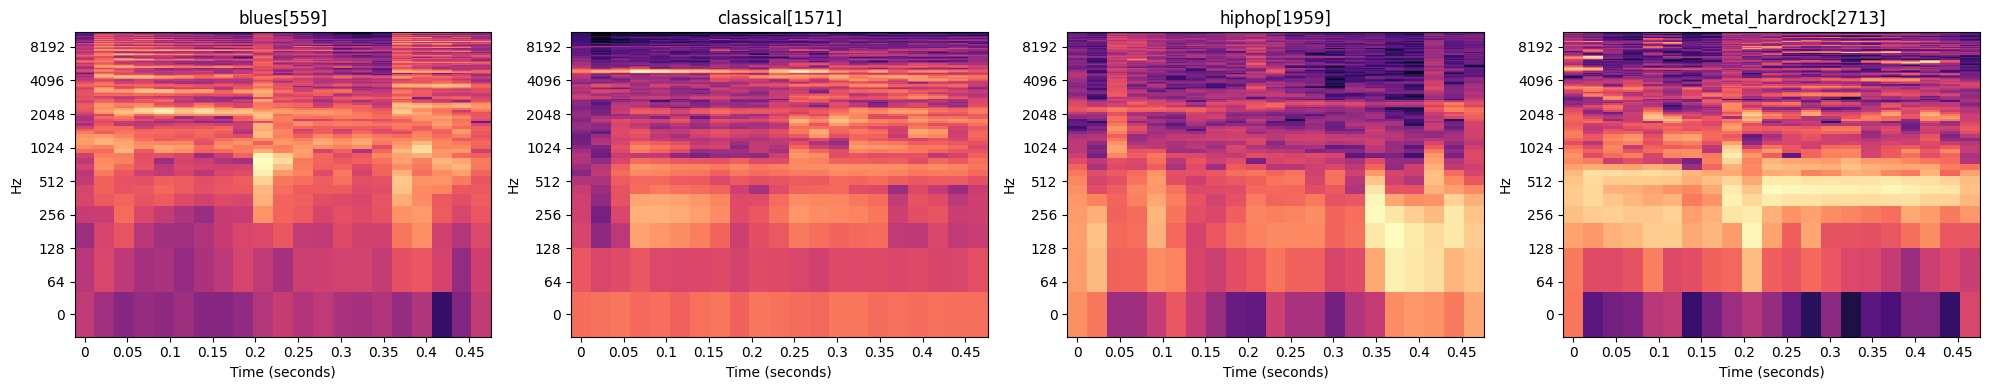

In [ ]:
show_melgrams(train_dataset)

Defining the convolutional neural network:

In [ ]:
class ConvolutionalNN(nn.Module):
    def __init__(self):
        super(ConvolutionalNN, self).__init__()

        self.output_classes = 4                                        #we have 4 types of output classes

        self.conv_layers = nn.Sequential(                              #convolutional layers of the cnn
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=5),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5),
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=5)
        )

        self.fc_input_size = self._get_fc_input_size()

        self.fc_layers = nn.Sequential(                                #fully conected layers of the cnn
            nn.Flatten(),
            nn.Linear(self.fc_input_size, 1024),
            nn.Linear(1024, 256),
            nn.Linear(256, 32),
            nn.Linear(32, self.output_classes)
        )

    #finding the input dimensions for the fully connected level
    def _get_fc_input_size(self):
        x = torch.zeros(1, 1, 21, 128)
        x = self.conv_layers(x)
        return x.numel()

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

Training the model on CPU and on GPU:

In [ ]:
learning_rate = 0.002
num_epochs = 30
device = "cuda" if torch.cuda.is_available() else "cpu"

model = ConvolutionalNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

train(model,train_melgrams,val_melgrams,loss_fn,optimizer,num_epochs,device,print_out=True,best_model_path="best_model.pth")

model = ConvolutionalNN()
model.load_state_dict(torch.load("best_model.pth",weights_only=True))
model.to(device)
loss, accuracy, f1, conf_matrix,_ = evaluate(model, test_melgrams, loss_fn, device)

Training started on cuda. Total number of batches: 200

Epoch 1/30 | Batch 100/200 | Loss: nan
Epoch 1/30 | Batch 200/200 | Loss: nan
Epoch 1/30 | Average Loss: nan | Validation f1 score: 0.1000
----------------------------------------
Epoch 2/30 | Batch 100/200 | Loss: nan
Epoch 2/30 | Batch 200/200 | Loss: nan
Epoch 2/30 | Average Loss: nan | Validation f1 score: 0.1000
----------------------------------------
Epoch 3/30 | Batch 100/200 | Loss: nan
Epoch 3/30 | Batch 200/200 | Loss: nan
Epoch 3/30 | Average Loss: nan | Validation f1 score: 0.1000
----------------------------------------
Epoch 4/30 | Batch 100/200 | Loss: nan
Epoch 4/30 | Batch 200/200 | Loss: nan
Epoch 4/30 | Average Loss: nan | Validation f1 score: 0.1000
----------------------------------------
Epoch 5/30 | Batch 100/200 | Loss: nan
Epoch 5/30 | Batch 200/200 | Loss: nan
Epoch 5/30 | Average Loss: nan | Validation f1 score: 0.1000
----------------------------------------
Epoch 6/30 | Batch 100/200 | Loss: nan
Epoch

The loss value reveals that the model cannot be trained.
In particular, the loss becomes very large and this is why it appears as Nan. This is due to the fact that we use multiple convolution layers, which produce high dimensional feature maps, and we are not using any pooling technique to downscale their dimensions.


We train again on GPU and compare elapsed times.

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
learning_rate = 0.002
num_epochs = 30

model = ConvolutionalNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

train(model,train_melgrams,val_melgrams,loss_fn,optimizer,num_epochs,device,print_out=True,best_model_path="best_model.pth")

model = ConvolutionalNN()
model.load_state_dict(torch.load("best_model.pth",weights_only=True))
model.to(device)
loss, accuracy, f1, conf_matrix,_ = evaluate(model, test_melgrams, loss_fn, device)

Training started on cuda. Total number of batches: 200

Epoch 1/30 | Batch 100/200 | Loss: nan
Epoch 1/30 | Batch 200/200 | Loss: nan
Epoch 1/30 | Average Loss: nan | Validation f1 score: 0.1000
----------------------------------------
Epoch 2/30 | Batch 100/200 | Loss: nan
Epoch 2/30 | Batch 200/200 | Loss: nan
Epoch 2/30 | Average Loss: nan | Validation f1 score: 0.1000
----------------------------------------
Epoch 3/30 | Batch 100/200 | Loss: nan
Epoch 3/30 | Batch 200/200 | Loss: nan
Epoch 3/30 | Average Loss: nan | Validation f1 score: 0.1000
----------------------------------------
Epoch 4/30 | Batch 100/200 | Loss: nan
Epoch 4/30 | Batch 200/200 | Loss: nan
Epoch 4/30 | Average Loss: nan | Validation f1 score: 0.1000
----------------------------------------
Epoch 5/30 | Batch 100/200 | Loss: nan
Epoch 5/30 | Batch 200/200 | Loss: nan
Epoch 5/30 | Average Loss: nan | Validation f1 score: 0.1000
----------------------------------------
Epoch 6/30 | Batch 100/200 | Loss: nan
Epoch

We observe that training our CNN on the GPU is faster than it is on the CPU. The GPU can better handle the matrix operations that occur when training a convolutional neural network. 

If we were to compare the current elapsed times with those of the previous section, we would conclude that training our feed forward network was fast both on the CPU and on the GPU. This is due to the fact that our FFN handles relatively smaller 1D input vectors and performs simple linear operations through each layer. On the other hand, our CNN works on multidimensional data.

Pooling and padding: We are introducing max pooling and padding to train our CNN. Max pooling helps to train our model by reducing the high dimensionality of our feature maps. Padding is used to preserve information in the edges. Without padding information in feature maps is mostly derived from pixels in the center of images. With padding filters can slide more times over the edges of our 2D data and capture local information that was not captured before.

In [ ]:
class ConvolutionalNN(nn.Module):
    def __init__(self):
        super(ConvolutionalNN, self).__init__()

        self.output_classes = 4                                           #we have 4 types of output classes

        self.conv_layers = nn.Sequential(                                 #Convolutional layers of the cnn
            nn.Conv2d(1, 16, kernel_size=5, padding=2),          #adding padding
            nn.MaxPool2d(kernel_size=2),                         #adding max pooling
            nn.Conv2d(16, 32, kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64, 128, kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2),
        )

        self.fc_input_size = self._get_fc_input_size()

        self.fc_layers = nn.Sequential(                               #Fully conected layers of the cnn
            nn.Flatten(),
            nn.Linear(self.fc_input_size, 1024),
            nn.Linear(1024, 256),
            nn.Linear(256, 32),
            nn.Linear(32, self.output_classes)
        )

    #finding the input dimensions for the fully connected level
    def _get_fc_input_size(self):
        x = torch.zeros(1, 1, 21, 128)
        x = self.conv_layers(x)
        return x.numel()


    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
learning_rate = 0.002
num_epochs = 30

model = ConvolutionalNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

train(model,train_melgrams,val_melgrams,loss_fn,optimizer,num_epochs,device,print_out=True,best_model_path="best_model.pth")

model = ConvolutionalNN()
model.load_state_dict(torch.load("best_model.pth"))
model.to(device)

loss, accuracy, f1, conf_matrix,_ = evaluate(model, test_melgrams, loss_fn, device)

Training started on cuda. Total number of batches: 200

Epoch 1/30 | Batch 100/200 | Loss: 1.4682
Epoch 1/30 | Batch 200/200 | Loss: 1.1748
Epoch 1/30 | Average Loss: 1.3225 | Validation f1 score: 0.3087
----------------------------------------
Epoch 2/30 | Batch 100/200 | Loss: 0.9966
Epoch 2/30 | Batch 200/200 | Loss: 1.0111
Epoch 2/30 | Average Loss: 1.1483 | Validation f1 score: 0.4267
----------------------------------------
Epoch 3/30 | Batch 100/200 | Loss: 0.8473
Epoch 3/30 | Batch 200/200 | Loss: 1.0476
Epoch 3/30 | Average Loss: 1.0018 | Validation f1 score: 0.4870
----------------------------------------
Epoch 4/30 | Batch 100/200 | Loss: 0.7311
Epoch 4/30 | Batch 200/200 | Loss: 0.6010
Epoch 4/30 | Average Loss: 0.9025 | Validation f1 score: 0.5348
----------------------------------------
Epoch 5/30 | Batch 100/200 | Loss: 0.7421
Epoch 5/30 | Batch 200/200 | Loss: 0.7786
Epoch 5/30 | Average Loss: 0.8345 | Validation f1 score: 0.5944
----------------------------------------

We observe that even from an early stage just by applying max pooling and padding our scores are acceptable. In particular, f1 score is > 0.70 which is considered a good score. The confusion matrix reveals that the number of true positives for most classes is high.

Training our model was also faster than in the previous section. That is easily explained by the fact that using max pooling reduces dimensions and therefore is computationally less expensive.

Activation Functions: We are now using activation functions to help our model learn more complex non-linear structures.

In [ ]:
class ConvolutionalNN(nn.Module):
    def __init__(self):
        super(ConvolutionalNN, self).__init__()

        self.output_classes = 4                                        #we have 4 types of output classes

        self.conv_layers = nn.Sequential(                                #convolutional layers of the cnn
            nn.Conv2d(1, 16, kernel_size=5, padding=2),
            nn.ReLU(),                                #adding Relu activation function after convolution, before pooling
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64, 128, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.fc_input_size = self._get_fc_input_size()

        self.fc_layers = nn.Sequential(                                #fully conected layers of the cnn
            nn.Flatten(),
            nn.ReLU(),                                #adding Relu activation function
            nn.Linear(self.fc_input_size, 1024),
            nn.ReLU(),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Linear(32, self.output_classes)
        )

    #finding the input dimensions for the fully connected level
    def _get_fc_input_size(self):
        x = torch.zeros(1, 1, 21, 128)
        x = self.conv_layers(x)
        return x.numel()


    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = ConvolutionalNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)
train(model,train_melgrams,val_melgrams,loss_fn,optimizer, num_epochs, device,print_out=True, best_model_path="best_model.pth")

model = ConvolutionalNN()
model.load_state_dict(torch.load("best_model.pth"))
model.to(device)

loss, accuracy, f1, conf_matrix,_ = evaluate(model, test_melgrams, loss_fn, device)

Training started on cuda. Total number of batches: 200

Epoch 1/30 | Batch 100/200 | Loss: 1.3992
Epoch 1/30 | Batch 200/200 | Loss: 1.3622
Epoch 1/30 | Average Loss: 1.3837 | Validation f1 score: 0.2492
----------------------------------------
Epoch 2/30 | Batch 100/200 | Loss: 1.3362
Epoch 2/30 | Batch 200/200 | Loss: 1.3610
Epoch 2/30 | Average Loss: 1.3623 | Validation f1 score: 0.3545
----------------------------------------
Epoch 3/30 | Batch 100/200 | Loss: 1.2988
Epoch 3/30 | Batch 200/200 | Loss: 1.3559
Epoch 3/30 | Average Loss: 1.3046 | Validation f1 score: 0.1725
----------------------------------------
Epoch 4/30 | Batch 100/200 | Loss: 1.2189
Epoch 4/30 | Batch 200/200 | Loss: 0.9654
Epoch 4/30 | Average Loss: 1.2380 | Validation f1 score: 0.1600
----------------------------------------
Epoch 5/30 | Batch 100/200 | Loss: 0.9725
Epoch 5/30 | Batch 200/200 | Loss: 0.9678
Epoch 5/30 | Average Loss: 1.1833 | Validation f1 score: 0.3948
----------------------------------------

The model with the best performance on f1 score is found during the last epochs. This is an indication that the model needs more epochs for training.

Question 3 - Improving the performance:

In this section we are trying to further improve the performance of our model and to be able to compare results we are setting a seed for our libraries.

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

In [ ]:
learning_rate = 0.002
num_epochs = 30
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
for i in range(2):

  set_seed(42)
  model = ConvolutionalNN()
  model.to(device)
  loss_fn = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=learning_rate)

  train(model, train_melgrams, val_melgrams, loss_fn, optimizer, num_epochs, device,print_out=True, best_model_path="best_model.pth")

  model = ConvolutionalNN()
  model.load_state_dict(torch.load("best_model.pth"))
  model.to(device)

  loss, accuracy, f1, conf_matrix,_ = evaluate(model, test_melgrams, loss_fn, device)

Training started on cuda. Total number of batches: 200

Epoch 1/30 | Batch 100/200 | Loss: 1.3687
Epoch 1/30 | Batch 200/200 | Loss: 1.3454
Epoch 1/30 | Average Loss: 1.3788 | Validation f1 score: 0.2556
----------------------------------------
Epoch 2/30 | Batch 100/200 | Loss: 1.2769
Epoch 2/30 | Batch 200/200 | Loss: 1.3725
Epoch 2/30 | Average Loss: 1.3356 | Validation f1 score: 0.2509
----------------------------------------
Epoch 3/30 | Batch 100/200 | Loss: 1.2349
Epoch 3/30 | Batch 200/200 | Loss: 1.1401
Epoch 3/30 | Average Loss: 1.2562 | Validation f1 score: 0.3489
----------------------------------------
Epoch 4/30 | Batch 100/200 | Loss: 1.0795
Epoch 4/30 | Batch 200/200 | Loss: 1.3333
Epoch 4/30 | Average Loss: 1.2094 | Validation f1 score: 0.2744
----------------------------------------
Epoch 5/30 | Batch 100/200 | Loss: 1.1372
Epoch 5/30 | Batch 200/200 | Loss: 1.6130
Epoch 5/30 | Average Loss: 1.1560 | Validation f1 score: 0.3016
----------------------------------------

Using optimization algorithms:

In [ ]:
results = []
optimizers_dict = {
    "SGD": optim.SGD,
    "Adam": optim.Adam,
    "AdamW": optim.AdamW,
    "RMSprop": optim.RMSprop,
    "Adagrad": optim.Adagrad,
    "Adadelta": optim.Adadelta,
    "Adamax": optim.Adamax,
    "ASGD": optim.ASGD,
    "Rprop": optim.Rprop,
    "NAdam": optim.NAdam,
    "RAdam": optim.RAdam,
}

for name, optimizer_class in optimizers_dict.items():
    set_seed(42)
    model = ConvolutionalNN().to(device)
    optimizer = optimizer_class(model.parameters(), lr=learning_rate)
    loss_fn = nn.CrossEntropyLoss()

    print(f"Optimizer used: {name}")
    print("-"*20)

    train(model,train_melgrams,val_melgrams,loss_fn,optimizer,num_epochs,device,print_out=False,best_model_path="best_model_cnn.pth")

    new_model = ConvolutionalNN().to(device)
    new_model.load_state_dict(torch.load("best_model_cnn.pth"))

    _,accuracy, f1,_,_ = evaluate(new_model, test_melgrams, loss_fn, device)
    results.append({"Optimizer": name, "Accuracy": accuracy, "F1 Score": f1})

results_df = pd.DataFrame(results)
results_df = results_df.set_index("Optimizer").T

Optimizer used: SGD
--------------------
Evaluation
Average Loss        : 0.8702
Accuracy            : 0.6417
F1 Macro-Averaged   : 0.6454

Confusion Matrix:
----------------------------------------
  194    19    55    56
   42   232    15     8
   41     2   293    20
  111    14   110   164


Optimizer used: Adam
--------------------
Evaluation
Average Loss        : 1.3876
Accuracy            : 0.2355
F1 Macro-Averaged   : 0.0953

Confusion Matrix:
----------------------------------------
  324     0     0     0
  297     0     0     0
  356     0     0     0
  399     0     0     0


Optimizer used: AdamW
--------------------
Evaluation
Average Loss        : 1.3890
Accuracy            : 0.2355
F1 Macro-Averaged   : 0.0953

Confusion Matrix:
----------------------------------------
  324     0     0     0
  297     0     0     0
  356     0     0     0
  399     0     0     0


Optimizer used: RMSprop
--------------------
Evaluation
Average Loss        : 1.3908
Accuracy            :

In [ ]:
print("Results Table:")
results_df

Results Table:


Optimizer,SGD,Adam,AdamW,RMSprop,Adagrad,Adadelta,Adamax,ASGD,Rprop,NAdam,RAdam
Accuracy,0.641715,0.235465,0.235465,0.235465,0.735465,0.497820,0.723837,0.654070,0.603924,0.710756,0.676599
F1 Score,0.645367,0.095294,0.095294,0.095294,0.743884,0.479645,0.729458,0.657389,0.604207,0.710059,0.686312


The highest accuracy and f1 scores are achieved by Adamax, NAdam and Adagrad with an accuracy between 0.71-0.73 and an f1 score between 0.71-0.74.


Acceptable scores are also achieved by the ASGD and RAdam optimizers with an accuracy and an f1 score > 0.65.

Very low scores are produced by  Adam, AdamW, Adadelta and RMSprop.

Batch Normalization: We are adding batch normalization on each convolutional layer before our activation functions.

In [ ]:
class ConvolutionalNN(nn.Module):
    def __init__(self):
        super(ConvolutionalNN, self).__init__()

        self.output_classes = 4                                        #we have 4 types of output classes

        self.conv_layers = nn.Sequential(                                #convolutional layers of the cnn
            nn.Conv2d(1, 16, kernel_size=5, padding=2),
            nn.BatchNorm2d(16),
            nn.ReLU(),                                #adding Relu activation function after convolution, before pooling
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.fc_input_size = self._get_fc_input_size()

        self.fc_layers = nn.Sequential(                                #fully conected layers of the cnn
            nn.Flatten(),
            nn.ReLU(),                                #adding Relu activation function
            nn.Linear(self.fc_input_size, 1024),
            nn.ReLU(),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Linear(32, self.output_classes)
        )

    #finding the input dimensions for the fully connected level
    def _get_fc_input_size(self):
        x = torch.zeros(1, 1, 21, 128)
        x = self.conv_layers(x)
        return x.numel()


    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

Regularization: In this part we are experimenting with different (i) weight decay and (ii) dropout values.

In [ ]:
num_epochs = 60
device = "cuda" if torch.cuda.is_available() else "cpu"
weight_decay_vals = [0.001,0.0001,0.00001,0.000001]
results = []

for weight_decay in weight_decay_vals:
    set_seed(42)
    model = ConvolutionalNN().to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.002, weight_decay=weight_decay)

    print(f"Training with weight_decay={weight_decay}")
    print("-" * 20)

    train(model, train_melgrams, val_melgrams, loss_fn, optimizer, num_epochs, device,
          print_out=False, best_model_path="best_model_cnn.pth")

    new_model = ConvolutionalNN().to(device)
    new_model.load_state_dict(torch.load("best_model_cnn.pth"))

    _, accuracy, f1, _,_ = evaluate(new_model, test_melgrams, loss_fn, device)

    results.append({"Weight Decay": weight_decay,"Accuracy": accuracy,"F1 Score": f1})

results_df = pd.DataFrame(results)

Training with weight_decay=0.001
--------------------
Evaluation
Average Loss        : 0.6203
Accuracy            : 0.7442
F1 Macro-Averaged   : 0.7479

Confusion Matrix:
----------------------------------------
  194    12    56    62
   35   256     1     5
   40     2   298    16
   74    11    38   276


Training with weight_decay=0.0001
--------------------
Evaluation
Average Loss        : 0.6181
Accuracy            : 0.7493
F1 Macro-Averaged   : 0.7530

Confusion Matrix:
----------------------------------------
  199    14    54    57
   30   261     1     5
   42     2   296    16
   75    12    37   275


Training with weight_decay=1e-05
--------------------
Evaluation
Average Loss        : 0.6094
Accuracy            : 0.7631
F1 Macro-Averaged   : 0.7643

Confusion Matrix:
----------------------------------------
  194    21    38    71
   11   281     0     5
   37     3   297    19
   73    19    29   278


Training with weight_decay=1e-06
--------------------
Evaluation
Aver

In [ ]:
print("\nResults for weight_decay:")
results_df


Results for weight_decay:


,Weight Decay,Accuracy,F1 Score
0,0.001000,0.744186,0.747871
1,0.000100,0.749273,0.752974
2,0.000010,0.763081,0.764349
3,0.000001,0.744913,0.748486


Redefining our CNN to support dropout:

In [ ]:
class ConvolutionalNN(nn.Module):
    def __init__(self,dropout_val):
        super(ConvolutionalNN, self).__init__()

        self.output_classes = 4                                        #we have 4 types of output classes

        self.conv_layers = nn.Sequential(                                #convolutional layers of the cnn
            nn.Conv2d(1, 16, kernel_size=5, padding=2),
            nn.BatchNorm2d(16),
            nn.ReLU(),                                #adding Relu activation function after convolution, before pooling
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.fc_input_size = self._get_fc_input_size()

        self.fc_layers = nn.Sequential(                                #fully conected layers of the cnn
            nn.Flatten(),
            nn.ReLU(),                                #adding Relu activation function
            nn.Dropout(dropout_val),
            nn.Linear(self.fc_input_size, 1024),
            nn.ReLU(),
            nn.Dropout(dropout_val),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(dropout_val),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Dropout(dropout_val),
            nn.Linear(32, self.output_classes)
        )

    #finding the input dimensions for the fully connected level
    def _get_fc_input_size(self):
        x = torch.zeros(1, 1, 21, 128)
        x = self.conv_layers(x)
        return x.numel()

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

In [ ]:
num_epochs = 60
device = "cuda" if torch.cuda.is_available() else "cpu"
dropout_vals = [0.3,0.4,0.5,0.6]
results = []

for dropout_value in dropout_vals:
    set_seed(42)
    model = ConvolutionalNN(dropout_value).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.002, weight_decay=0.0)

    print(f"Training with dropout={dropout_value}")
    print("-" * 20)

    train(model,train_melgrams,val_melgrams,loss_fn,optimizer,num_epochs,device,print_out=False, best_model_path="best_model_cnn.pth")

    new_model = ConvolutionalNN(dropout_value).to(device)
    new_model.load_state_dict(torch.load("best_model_cnn.pth"))

    _, accuracy, f1, _,_= evaluate(new_model, test_melgrams, loss_fn, device)

    results.append({"Dropout": dropout_value,"Accuracy": accuracy,"F1 Score": f1})

results_df = pd.DataFrame(results)

Training with dropout=0.3
--------------------
Evaluation
Average Loss        : 0.6252
Accuracy            : 0.7427
F1 Macro-Averaged   : 0.7484

Confusion Matrix:
----------------------------------------
  203     9    55    57
   38   255     0     4
   40     3   296    17
   84     9    38   268


Training with dropout=0.4
--------------------
Evaluation
Average Loss        : 0.6090
Accuracy            : 0.7558
F1 Macro-Averaged   : 0.7568

Confusion Matrix:
----------------------------------------
  186    23    44    71
   12   280     0     5
   40     3   296    17
   74    13    34   278


Training with dropout=0.5
--------------------
Evaluation
Average Loss        : 0.6310
Accuracy            : 0.7413
F1 Macro-Averaged   : 0.7453

Confusion Matrix:
----------------------------------------
  194    13    56    61
   32   259     0     6
   38     3   296    19
   82    11    35   271


Training with dropout=0.6
--------------------
Evaluation
Average Loss        : 0.6114
Accu

In [ ]:
print("\nResults for dropout:")
print(results_df)


Results for dropout:
   Dropout  Accuracy  F1 Score
0      0.3  0.742733  0.748352
1      0.4  0.755814  0.756758
2      0.5  0.741279  0.745328
3      0.6  0.757994  0.759299


We combine both weight decay and dropout using the values that achieved higher f1 scores (0.6 for dropout, 0.00001 for weight decay).

In [ ]:
dropout_best = 0.6
weight_decay_best = 0.00001
set_seed(42)

model = ConvolutionalNN(dropout_best).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate, weight_decay=weight_decay_best)

print(f"Training with dropout={dropout_best} and weight_decay={weight_decay_best}")
print("-" * 40)

train(model, train_melgrams, val_melgrams, loss_fn, optimizer, num_epochs, device,print_out=False, best_model_path="best_model_cnn.pth")

new_model = ConvolutionalNN(dropout_best).to(device)
new_model.load_state_dict(torch.load("best_model_cnn.pth"))

_, accuracy, f1, _,_ = evaluate(new_model, test_melgrams, loss_fn, device)

Training with dropout=0.6 and weight_decay=1e-05
----------------------------------------
Evaluation
Average Loss        : 0.6186
Accuracy            : 0.7544
F1 Macro-Averaged   : 0.7551

Confusion Matrix:
----------------------------------------
  181    21    44    78
   14   277     0     6
   45     3   292    16
   66    12    33   288




The accuracy and f1 scores we achieve on the test set is around 0.75.

Question 4 - Testing:

Inference: We are using our evaluation function from above to classify various youtube musical pieces.

In [ ]:
!pip install yt-dlp pydub

import yt_dlp
from pydub import AudioSegment
import os

def download_youtube(youtube_url, output_path="output.wav"):
    try:
        # Download audio using yt_dlp
        ydl_opts = {
            'format': 'bestaudio/best',
            'outtmpl': 'downloaded_audio.%(ext)s',
            'postprocessors': [{
                'key': 'FFmpegExtractAudio',
                'preferredcodec': 'mp3',
                'preferredquality': '192',
            }],
        }

        with yt_dlp.YoutubeDL(ydl_opts) as ydl:
            ydl.download([youtube_url])

        audio_file = "downloaded_audio.mp3"
        audio = AudioSegment.from_file(audio_file)
        audio.export(output_path, format="wav")

        os.remove(audio_file)

    except Exception as e:
        print(f"Download failed: {e}")
        raise

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 173.3/173.3 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 49.3 MB/s eta 0:00:00


In [ ]:
import os
import librosa
import numpy as np

window_length = (50 * 1e-3)
hop_length = (50 * 1e-3)
mel_time_size = 21

def load_wav(filename):
    """Rea audio file and return audio signal and sampling frequency"""
    if not os.path.exists(filename):
        raise FileNotFoundError
    # Load file using librosa
    x, fs = librosa.load(filename, sr=None)
    return x, fs


def melspectrogram(x=None, fs=None, n_fft=None, hop_length=None,
                   fuse=False):
    """Returns a mel spectrogram."""

    if x is None:
        return None
    # Set some values
    if n_fft is None:
        n_fft = int(window_length * fs)
    if hop_length is None:
        hop_length = int(hop_length * fs)
    # Get spectrogram
    spectrogram = librosa.feature.melspectrogram(y=x, sr=fs, n_fft=n_fft,
                                                 hop_length=hop_length)
    # Convert to MEL-Scale
    spectrogram_dB = librosa.power_to_db(spectrogram, ref=np.max)  # (n_mel,t)

    if fuse:
        chroma = librosa.feature.chroma_stft(y=x, sr=fs, n_fft=n_fft,
                                             hop_length=hop_length)
        chroma_dB = librosa.power_to_db(chroma)
        out = np.concatenate((spectrogram_dB.T, chroma_dB.T), axis=1)
    else:
        # Transpose to return (time,n_mel)
        out = spectrogram_dB.T
    return out


def get_melgrams(file):
    signal, fs = load_wav(file)

    segment_length = int((mel_time_size - 1) * window_length * fs)
    sequence_length = signal.shape[0]
    progress = 0
    segments = []
    while progress < sequence_length:
        if progress + segment_length > sequence_length:
            fill_data = sequence_length - progress
            empty_data = segment_length - fill_data
            feature = melspectrogram(
                np.pad(signal[progress:], (0, empty_data), 'constant'),
                fs=fs, n_fft=int(window_length * fs), hop_length=int(hop_length * fs))
            segments.append(feature)
        else:
            feature = melspectrogram(
                signal[progress:progress + segment_length],
                fs=fs, n_fft=int(window_length * fs), hop_length=int(hop_length * fs))

            segments.append(feature)
        progress += segment_length

    return segments


def youtube_to_melgram(url, title):
    download_youtube(url, output_path="output.wav")
    melgrams = get_melgrams("output.wav")
    np.save(f"{title}_melgrams.npy", melgrams)

In [ ]:
songs = [
    {"title": "Chopin_Nocturne", "genre": "classical", "url": "https://www.youtube.com/watch?v=9E6b3swbnWg"},
    {"title": "Four_Seasons", "genre": "classical", "url": "https://www.youtube.com/watch?v=GRxofEmo3HA"},
    {"title": "5th_Symphony", "genre": "classical", "url": "https://www.youtube.com/watch?v=wsz2KRqpMhI"},

    {"title": "The_Real_Slim_Shady", "genre": "hiphop", "url": "https://www.youtube.com/watch?v=eJO5HU_7_1w"},
    {"title": "Humble", "genre": "hiphop", "url": "https://www.youtube.com/watch?v=tvTRZJ-4EyI"},
    {"title": "In_Da_Club", "genre": "hiphop", "url": "https://www.youtube.com/watch?v=5qm8PH4xAss"},

    {"title": "How_Blue_Can_You_Get", "genre": "blues", "url": "https://www.youtube.com/watch?v=l45f28PzfCI"},
]

true_labels = {'blues': 0,'classical': 1,'hiphop': 2}
class_names = ["blues", "classical", "hiphop"]

for song in songs:        #Downloading songs
    youtube_to_melgram(song["url"], song["title"])

[youtube] Extracting URL: https://www.youtube.com/watch?v=9E6b3swbnWg
[youtube] 9E6b3swbnWg: Downloading webpage
[youtube] 9E6b3swbnWg: Downloading tv client config
[youtube] 9E6b3swbnWg: Downloading player b2858d36-main
[youtube] 9E6b3swbnWg: Downloading tv player API JSON
[youtube] 9E6b3swbnWg: Downloading ios player API JSON
[youtube] 9E6b3swbnWg: Downloading m3u8 information
[info] 9E6b3swbnWg: Downloading 1 format(s): 251
[download] Destination: downloaded_audio.webm
[download] 100% of    4.85MiB in 00:00:00 at 29.65MiB/s  
[ExtractAudio] Destination: downloaded_audio.mp3
Deleting original file downloaded_audio.webm (pass -k to keep)
[youtube] Extracting URL: https://www.youtube.com/watch?v=GRxofEmo3HA
[youtube] GRxofEmo3HA: Downloading webpage
[youtube] GRxofEmo3HA: Downloading tv client config
[youtube] GRxofEmo3HA: Downloading tv player API JSON
[youtube] GRxofEmo3HA: Downloading ios player API JSON
[youtube] GRxofEmo3HA: Downloading player b2858d36-main
[youtube] GRxofEmo3HA: 

In [ ]:
def plot(title, y_true, y_pred, class_names):
    timestamps = list(range(len(y_pred)))

    plt.figure(figsize=(9, 5))
    plt.title(f"{title}")
    plt.xlabel("Timestamps (seconds)")
    plt.ylabel("Music Genre")

    plt.scatter(timestamps, y_pred, color='deepskyblue', label="Predicted", s=30)
    plt.scatter(timestamps, y_true, color='orange', label="Actual", alpha=0.5, s=15)

    plt.yticks(range(len(class_names)), class_names)
    plt.legend()
    plt.grid(False)
    plt.show()

We choose the model that is going to be tested on real world data based on the experimentation we did in sections 2 and 3. We want our model to be able to generalize well and not overfit so we are using 0.3 as a value for dropout and 1e-5 for weight decay. We are using the Adamax optimizer.

In [ ]:
device = "cpu"
num_epochs = 60

set_seed(42)

model = ConvolutionalNN(0.3).to(device)
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adamax(model.parameters(), lr=0.001, weight_decay=1e-5)

train(model, train_melgrams, val_melgrams, loss_fn, optimizer, num_epochs, device,print_out=True, best_model_path="best_model_cnn.pth")

new_model = ConvolutionalNN(0.3).to(device)
new_model.load_state_dict(torch.load("best_model_cnn.pth"))

_, _, f1, _, _ = evaluate(new_model, test_melgrams, loss_fn, device, print_out=True)

Training started on cpu. Total number of batches: 200

Epoch 1/60 | Batch 100/200 | Loss: 0.9506
Epoch 1/60 | Batch 200/200 | Loss: 0.6638
Epoch 1/60 | Average Loss: 1.0377 | Validation f1 score: 0.6977
----------------------------------------
Epoch 2/60 | Batch 100/200 | Loss: 0.7116
Epoch 2/60 | Batch 200/200 | Loss: 0.9374
Epoch 2/60 | Average Loss: 0.6541 | Validation f1 score: 0.7319
----------------------------------------
Epoch 3/60 | Batch 100/200 | Loss: 0.4396
Epoch 3/60 | Batch 200/200 | Loss: 0.5340
Epoch 3/60 | Average Loss: 0.5982 | Validation f1 score: 0.7911
----------------------------------------
Epoch 4/60 | Batch 100/200 | Loss: 0.7461
Epoch 4/60 | Batch 200/200 | Loss: 0.5007
Epoch 4/60 | Average Loss: 0.5572 | Validation f1 score: 0.7790
----------------------------------------
Epoch 5/60 | Batch 100/200 | Loss: 0.4586
Epoch 5/60 | Batch 200/200 | Loss: 0.4789
Epoch 5/60 | Average Loss: 0.5112 | Validation f1 score: 0.7756
----------------------------------------


Chopin_Nocturne: 266/270 correct predictions. Accuracy: 98.52%


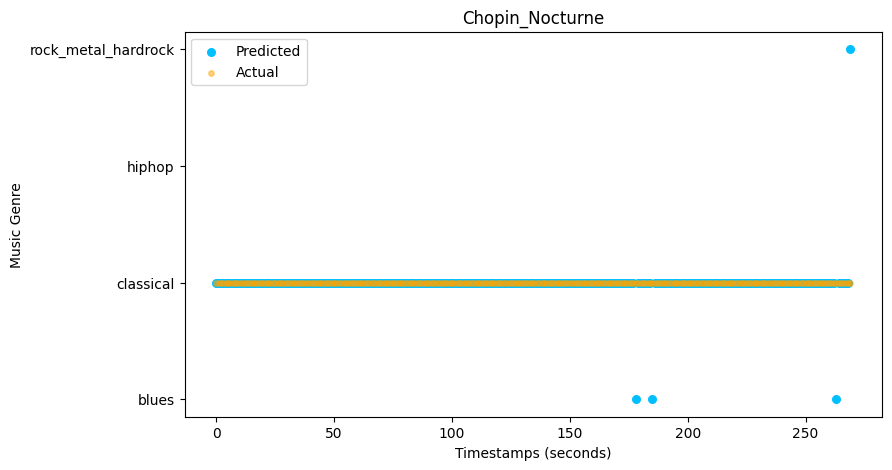

Four_Seasons: 2427/2520 correct predictions. Accuracy: 96.31%


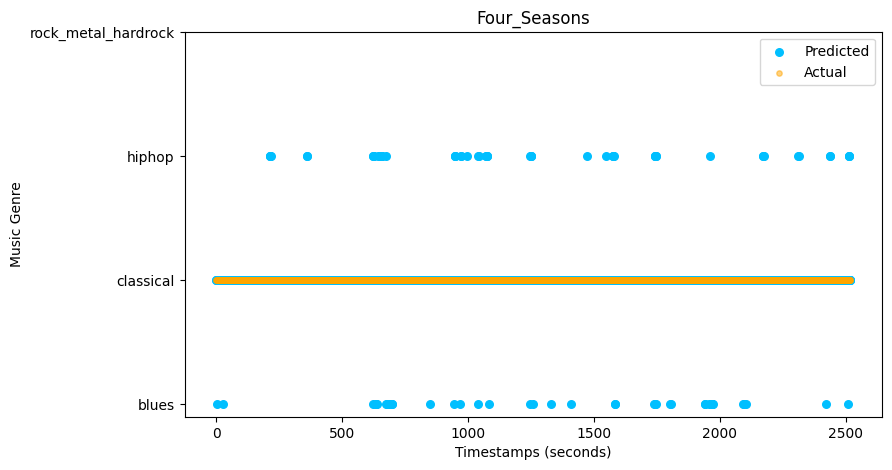

5th_Symphony: 398/422 correct predictions. Accuracy: 94.31%


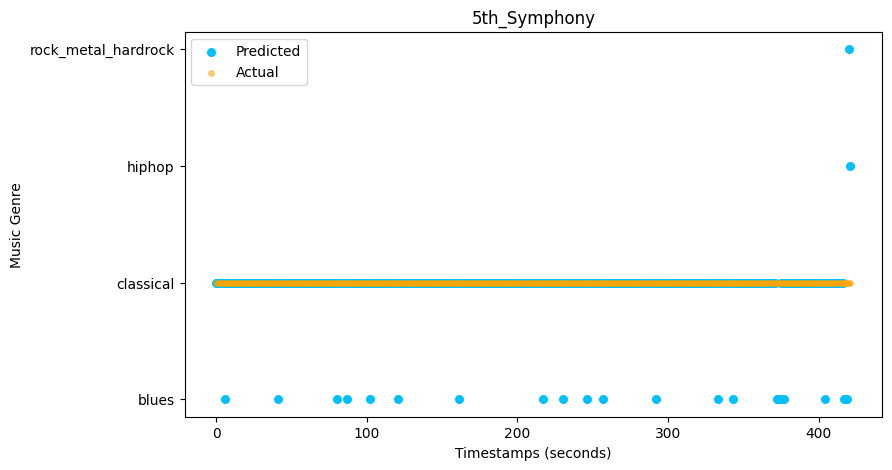


Average Accuracy for 'classical' songs: 96.23%


In [ ]:
set_seed(42)
total_correct = 0
total_samples = 0

for song in songs:
    if song["genre"] != "classical":
        continue

    title = song["title"]
    genre = song["genre"]
    genre_label = true_labels[genre]

    x = np.load(f"{title}_melgrams.npy", allow_pickle=True)
    x = np.expand_dims(x, axis=1)
    x = torch.from_numpy(x).float()

    y = torch.full((x.size(0),), genre_label, dtype=torch.long)
    dataset = melgrams_dataset(x, y, class_names)
    dataloader = DataLoader(dataset, batch_size=32, shuffle=False)

    _, accuracy, f1, _, y_preds = evaluate(new_model, dataloader, loss_fn, device, print_out=False)
    y_preds = np.array(y_preds)
    y_true = y.numpy()

    correct = (y_preds == y_true).sum()
    total = len(y_true)

    total_correct += correct
    total_samples += total

    print(f"{title}: {correct}/{total} correct predictions. Accuracy: {100 * correct / total:.2f}%")
    plot(title, y_true, y_preds, class_names)

avg_accuracy = 100 * total_correct / total_samples
print(f"\nAverage Accuracy for 'classical' songs: {avg_accuracy:.2f}%")

The_Real_Slim_Shady: 157/269 correct predictions. Accuracy: 58.36%


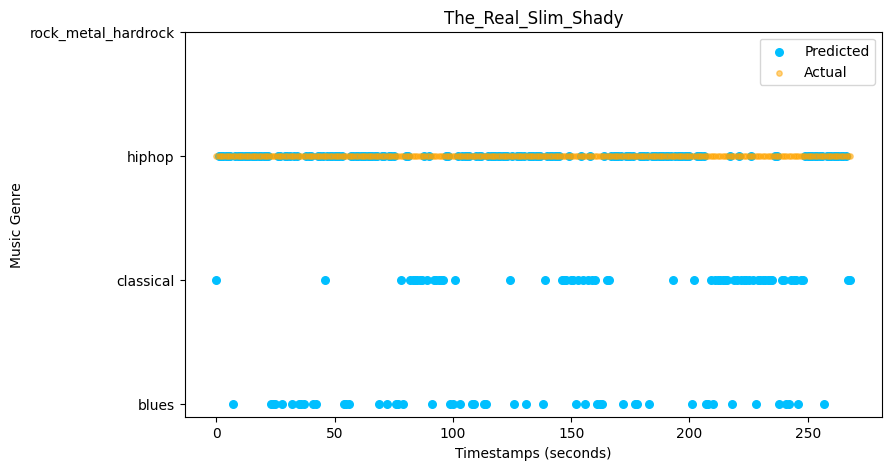

Humble: 103/184 correct predictions. Accuracy: 55.98%


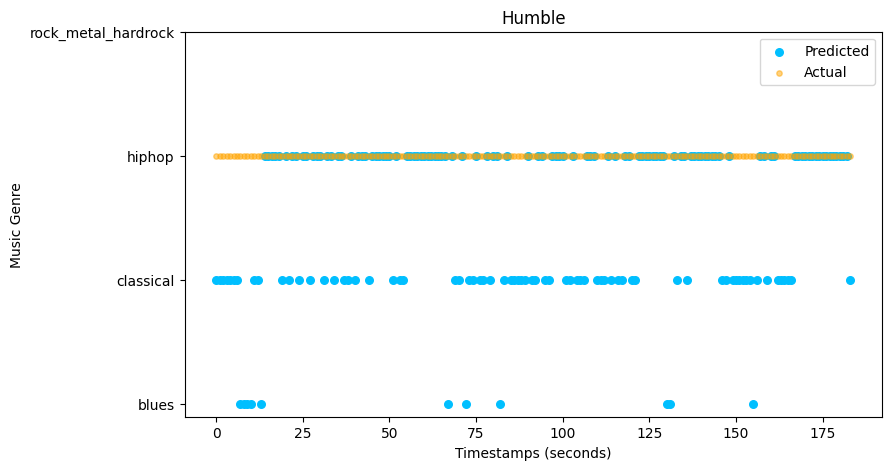

In_Da_Club: 109/248 correct predictions. Accuracy: 43.95%


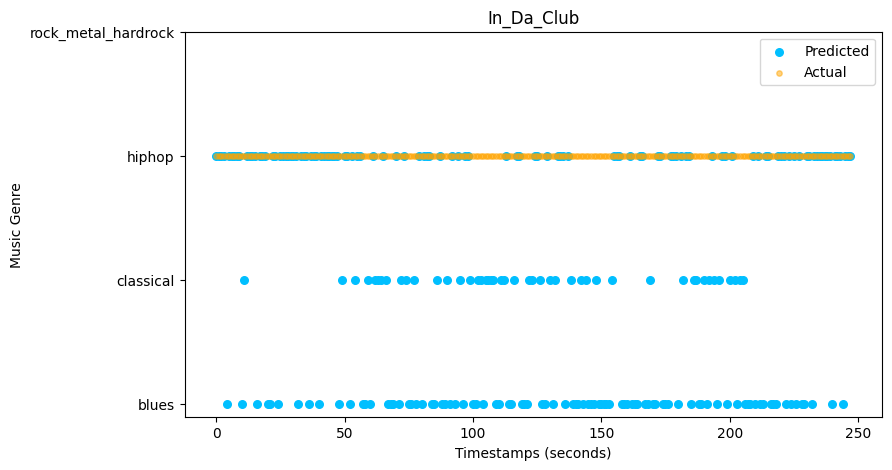


Average Accuracy for 'hiphop' songs: 52.64%


In [ ]:
set_seed(42)
total_correct = 0
total_samples = 0

for song in songs:
    if song["genre"] != "hiphop":
        continue

    title = song["title"]
    genre = song["genre"]
    genre_label = true_labels[genre]

    x = np.load(f"{title}_melgrams.npy", allow_pickle=True)
    x = np.expand_dims(x, axis=1)
    x = torch.from_numpy(x).float()

    y = torch.full((x.size(0),), genre_label, dtype=torch.long)
    dataset = melgrams_dataset(x, y, class_names)
    dataloader = DataLoader(dataset, batch_size=32, shuffle=False)

    _, acc, f1, _, y_preds = evaluate(new_model, dataloader, loss_fn, device, print_out=False)
    y_preds = np.array(y_preds)
    y_true = y.numpy()

    correct = (y_preds == y_true).sum()
    total = len(y_true)

    total_correct += correct
    total_samples += total

    print(f"{title}: {correct}/{total} correct predictions. Accuracy: {100 * correct / total:.2f}%")
    plot(title, y_true, y_preds, class_names)

avg_accuracy = 100 * total_correct / total_samples
print(f"\nAverage Accuracy for 'hiphop' songs: {avg_accuracy:.2f}%")

How_Blue_Can_You_Get: 192/313 correct predictions. Accuracy: 61.34%


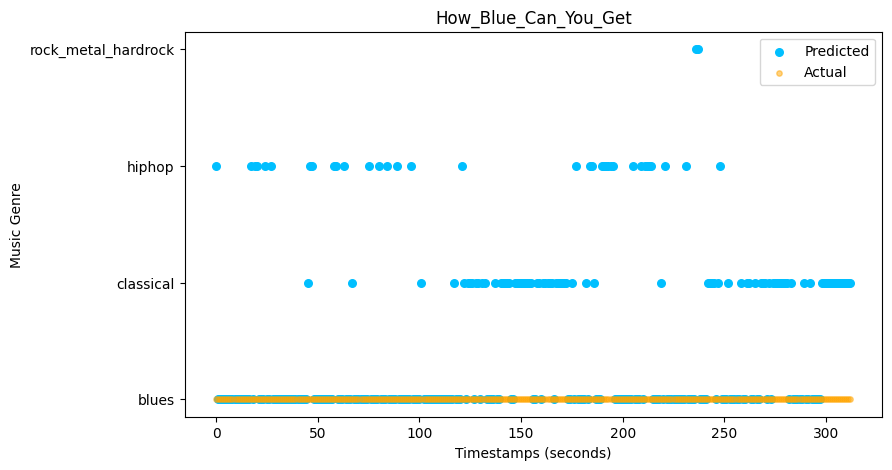

In [ ]:
set_seed(42)
for song in songs:
    if song["genre"] != "blues":
        continue

    title = song["title"]
    genre = song["genre"]
    genre_label = true_labels[genre]

    x = np.load(f"{title}_melgrams.npy", allow_pickle=True)
    x = np.expand_dims(x, axis=1)
    x = torch.from_numpy(x).float()

    y = torch.full((x.size(0),), genre_label, dtype=torch.long)
    dataset = melgrams_dataset(x, y, class_names)
    dataloader = DataLoader(dataset, batch_size=32, shuffle=False)

    _, acc, f1, _, y_preds = evaluate(new_model, dataloader, loss_fn, device, print_out=False)
    y_preds = np.array(y_preds)
    y_true = y.numpy()

    correct = (y_preds == y_true).sum()
    total = len(y_true)
    print(f"{title}: {correct}/{total} correct predictions. Accuracy: {100 * correct / total:.2f}%")
    plot(title, y_true, y_preds, class_names)